In [8]:
%pip install nltk
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
[nltk_data] Downloading package stopwords to C:\Users\Jahnvi
[nltk_data]     Pandey\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [9]:
data = pd.read_csv(r"C:\Users\Jahnvi Pandey\OneDrive\Documents\GlobalFakeNews_Research2026_v1.csv")
print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [10]:
print(data.head())

   id                                         title  \
0   1       Official Report on Politics Development   
1   2  Official Report on Entertainment Development   
2   3       Official Report on Politics Development   
3   4       Official Report on Politics Development   
4   5       Official Report on Politics Development   

                                           full_text source_name publish_date  \
0  This article provides detailed analysis based ...         BBC   2024-10-08   
1  This article provides detailed analysis based ...     Reuters   2024-04-14   
2  This article provides detailed analysis based ...         CNN   2025-08-27   
3  This article provides detailed analysis based ...         BBC   2024-08-11   
4  This article provides detailed analysis based ...         CNN   2025-07-28   

        category    country  label  sentiment_score  clickbait_score  \
0         Health         UK      0           0.1993           0.2196   
1  Entertainment  Australia      0    

In [11]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1200 non-null   int64  
 1   title                 1200 non-null   object 
 2   full_text             1200 non-null   object 
 3   source_name           1200 non-null   object 
 4   publish_date          1200 non-null   object 
 5   category              1200 non-null   object 
 6   country               1200 non-null   object 
 7   label                 1200 non-null   int64  
 8   sentiment_score       1200 non-null   float64
 9   clickbait_score       1200 non-null   float64
 10  emotional_word_ratio  1200 non-null   float64
 11  readability_score     1200 non-null   float64
 12  source_trust_score    1200 non-null   float64
 13  text_embedding        1200 non-null   object 
dtypes: float64(5), int64(2), object(7)
memory usage: 131.4+ KB
None


In [12]:
print(data.shape)

(1200, 14)


In [13]:
print(data.columns)

Index(['id', 'title', 'full_text', 'source_name', 'publish_date', 'category',
       'country', 'label', 'sentiment_score', 'clickbait_score',
       'emotional_word_ratio', 'readability_score', 'source_trust_score',
       'text_embedding'],
      dtype='object')


In [14]:
print(data.isnull().sum())

id                      0
title                   0
full_text               0
source_name             0
publish_date            0
category                0
country                 0
label                   0
sentiment_score         0
clickbait_score         0
emotional_word_ratio    0
readability_score       0
source_trust_score      0
text_embedding          0
dtype: int64


In [15]:
print(data.columns)

Index(['id', 'title', 'full_text', 'source_name', 'publish_date', 'category',
       'country', 'label', 'sentiment_score', 'clickbait_score',
       'emotional_word_ratio', 'readability_score', 'source_trust_score',
       'text_embedding'],
      dtype='object')


In [16]:
print("Duplicate Rows =", data.duplicated().sum())

Duplicate Rows = 0


In [17]:
data["full_text"] = data["full_text"].fillna("")

In [18]:
import re
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def clean_text(text):

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove punctuation and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove stopwords
    words = text.split()

    words = [word for word in words if word not in stop_words]

    return " ".join(words)

In [19]:
data["clean_text"] = data["full_text"].apply(clean_text)

In [20]:
print(data[["full_text", "clean_text"]].head())

                                           full_text  \
0  This article provides detailed analysis based ...   
1  This article provides detailed analysis based ...   
2  This article provides detailed analysis based ...   
3  This article provides detailed analysis based ...   
4  This article provides detailed analysis based ...   

                                          clean_text  
0  article provides detailed analysis based verif...  
1  article provides detailed analysis based verif...  
2  article provides detailed analysis based verif...  
3  article provides detailed analysis based verif...  
4  article provides detailed analysis based verif...  


In [21]:
data["tokens"] = data["clean_text"].apply(lambda x: x.split())
print(data["tokens"].head())

0    [article, provides, detailed, analysis, based,...
1    [article, provides, detailed, analysis, based,...
2    [article, provides, detailed, analysis, based,...
3    [article, provides, detailed, analysis, based,...
4    [article, provides, detailed, analysis, based,...
Name: tokens, dtype: object


In [22]:
print(data["label"].value_counts())


label
0    600
1    600
Name: count, dtype: int64


In [23]:
print(data["label"].value_counts())

label
0    600
1    600
Name: count, dtype: int64


In [24]:
stop_words = set(stopwords.words("english"))

In [25]:
def clean_text(text):

    # Convert into string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+', '', text)

    # Remove HTML Tags
    text = re.sub(r'<.*?>', '', text)

    # Remove Numbers
    text = re.sub(r'\d+', '', text)

    # Remove Punctuation
    text = re.sub(r'[^\w\s]', '', text)

    # Remove Extra Spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Manual Tokenization
    words = text.split()

    # Remove Stopwords
    words = [word for word in words if word not in stop_words]

    # Join words again
    cleaned_text = " ".join(words)

    return cleaned_text

In [26]:
data["clean_text"] = data["full_text"].apply(clean_text)
print(data[["full_text","clean_text"]].head())

                                           full_text  \
0  This article provides detailed analysis based ...   
1  This article provides detailed analysis based ...   
2  This article provides detailed analysis based ...   
3  This article provides detailed analysis based ...   
4  This article provides detailed analysis based ...   

                                          clean_text  
0  article provides detailed analysis based verif...  
1  article provides detailed analysis based verif...  
2  article provides detailed analysis based verif...  
3  article provides detailed analysis based verif...  
4  article provides detailed analysis based verif...  


In [27]:
data["tokens"] = data["clean_text"].apply(lambda x: x.split())
print(data["tokens"].head())

0    [article, provides, detailed, analysis, based,...
1    [article, provides, detailed, analysis, based,...
2    [article, provides, detailed, analysis, based,...
3    [article, provides, detailed, analysis, based,...
4    [article, provides, detailed, analysis, based,...
Name: tokens, dtype: object


In [28]:
data["word_count"] = data["tokens"].apply(len)
print(data["word_count"].head())

0    45
1    45
2    45
3    45
4    45
Name: word_count, dtype: int64


In [29]:
print(data[["full_text","clean_text","tokens","word_count"]].head())

                                           full_text  \
0  This article provides detailed analysis based ...   
1  This article provides detailed analysis based ...   
2  This article provides detailed analysis based ...   
3  This article provides detailed analysis based ...   
4  This article provides detailed analysis based ...   

                                          clean_text  \
0  article provides detailed analysis based verif...   
1  article provides detailed analysis based verif...   
2  article provides detailed analysis based verif...   
3  article provides detailed analysis based verif...   
4  article provides detailed analysis based verif...   

                                              tokens  word_count  
0  [article, provides, detailed, analysis, based,...          45  
1  [article, provides, detailed, analysis, based,...          45  
2  [article, provides, detailed, analysis, based,...          45  
3  [article, provides, detailed, analysis, based,...      

In [30]:
data.to_csv("Cleaned_Fake_News.csv",index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [31]:
print("Final Dataset Shape")
print(data.shape)

Final Dataset Shape
(1200, 17)


In [32]:
print(data.columns)

Index(['id', 'title', 'full_text', 'source_name', 'publish_date', 'category',
       'country', 'label', 'sentiment_score', 'clickbait_score',
       'emotional_word_ratio', 'readability_score', 'source_trust_score',
       'text_embedding', 'clean_text', 'tokens', 'word_count'],
      dtype='object')


In [33]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [34]:
data = pd.read_csv("Cleaned_Fake_News.csv")
print(data)

        id                                         title  \
0        1       Official Report on Politics Development   
1        2  Official Report on Entertainment Development   
2        3       Official Report on Politics Development   
3        4       Official Report on Politics Development   
4        5       Official Report on Politics Development   
...    ...                                           ...   
1195  1196       Shocking Truth About Business Revealed!   
1196  1197  Shocking Truth About Entertainment Revealed!   
1197  1198     Shocking Truth About Technology Revealed!   
1198  1199     Shocking Truth About Technology Revealed!   
1199  1200     Shocking Truth About Technology Revealed!   

                                              full_text      source_name  \
0     This article provides detailed analysis based ...              BBC   
1     This article provides detailed analysis based ...          Reuters   
2     This article provides detailed analysis based

In [35]:
print(data.head())

   id                                         title  \
0   1       Official Report on Politics Development   
1   2  Official Report on Entertainment Development   
2   3       Official Report on Politics Development   
3   4       Official Report on Politics Development   
4   5       Official Report on Politics Development   

                                           full_text source_name publish_date  \
0  This article provides detailed analysis based ...         BBC   2024-10-08   
1  This article provides detailed analysis based ...     Reuters   2024-04-14   
2  This article provides detailed analysis based ...         CNN   2025-08-27   
3  This article provides detailed analysis based ...         BBC   2024-08-11   
4  This article provides detailed analysis based ...         CNN   2025-07-28   

        category    country  label  sentiment_score  clickbait_score  \
0         Health         UK      0           0.1993           0.2196   
1  Entertainment  Australia      0    

In [36]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1200 non-null   int64  
 1   title                 1200 non-null   object 
 2   full_text             1200 non-null   object 
 3   source_name           1200 non-null   object 
 4   publish_date          1200 non-null   object 
 5   category              1200 non-null   object 
 6   country               1200 non-null   object 
 7   label                 1200 non-null   int64  
 8   sentiment_score       1200 non-null   float64
 9   clickbait_score       1200 non-null   float64
 10  emotional_word_ratio  1200 non-null   float64
 11  readability_score     1200 non-null   float64
 12  source_trust_score    1200 non-null   float64
 13  text_embedding        1200 non-null   object 
 14  clean_text            1200 non-null   object 
 15  tokens               

In [37]:
print(data.shape)

(1200, 17)


In [38]:
print(data.shape)

(1200, 17)


In [39]:
print(data["label"].value_counts())

label
0    600
1    600
Name: count, dtype: int64


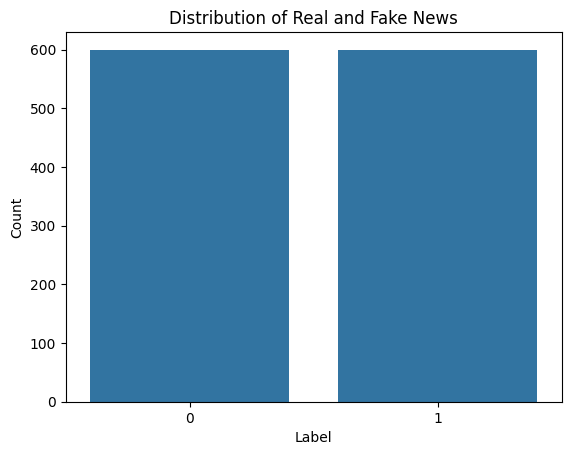

In [40]:
sns.countplot(x="label", data=data)

plt.title("Distribution of Real and Fake News")
plt.xlabel("Label")
plt.ylabel("Count")

plt.show()

In [41]:
data["word_count"] = data["clean_text"].apply(lambda x: len(str(x).split()))
print(data["word_count"].head())

0    45
1    45
2    45
3    45
4    45
Name: word_count, dtype: int64


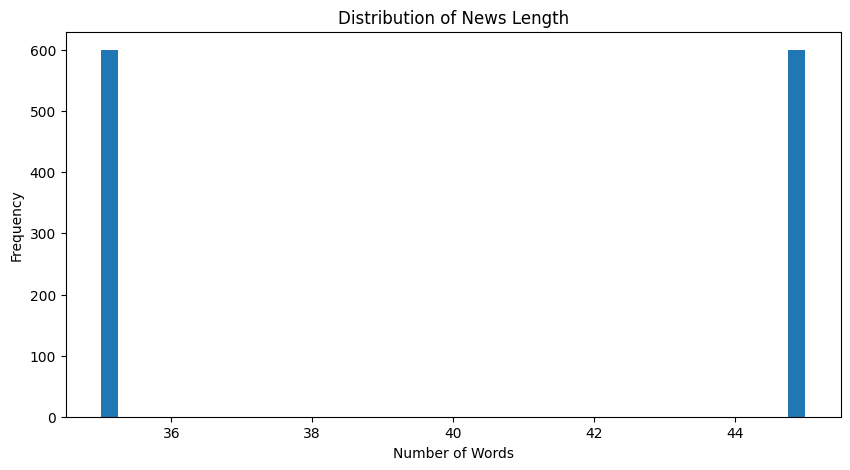

In [42]:
plt.figure(figsize=(10,5))

plt.hist(data["word_count"], bins=40)

plt.title("Distribution of News Length")

plt.xlabel("Number of Words")

plt.ylabel("Frequency")

plt.show()

In [43]:
all_words = " ".join(data["clean_text"])
words = all_words.split()
from collections import Counter
word_freq = Counter(words)
print(word_freq.most_common(20))

[('article', 3000), ('provides', 3000), ('detailed', 3000), ('analysis', 3000), ('based', 3000), ('verified', 3000), ('sources', 3000), ('official', 3000), ('statements', 3000), ('shocking', 3000), ('revelation', 3000), ('completely', 3000), ('change', 3000), ('believe', 3000), ('recent', 3000), ('events', 3000)]


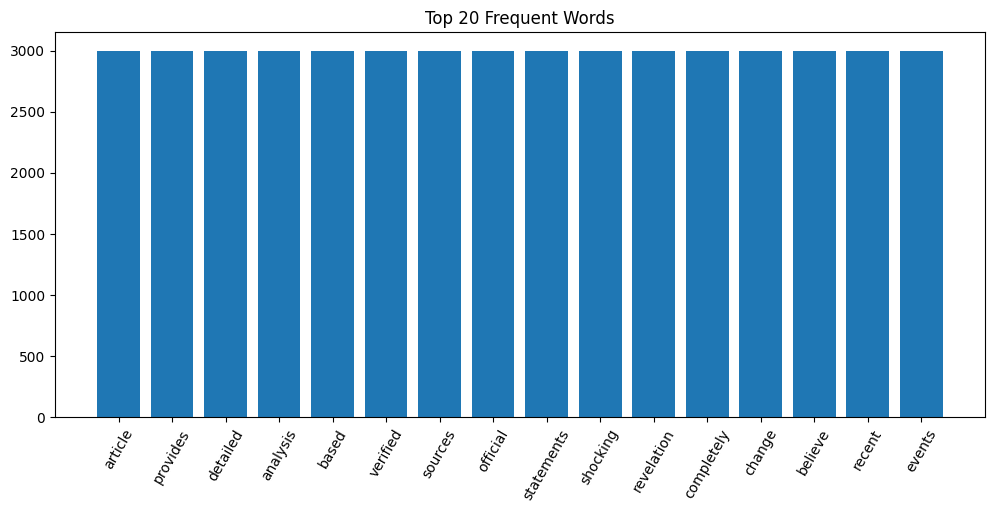

In [44]:
common = word_freq.most_common(20)

words = [i[0] for i in common]

counts = [i[1] for i in common]

plt.figure(figsize=(12,5))

plt.bar(words, counts)

plt.xticks(rotation=60)

plt.title("Top 20 Frequent Words")

plt.show()

In [45]:
pip install wordcloud

  Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl.metadata (3.5 kB)
Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl (306 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
from wordcloud import WordCloud

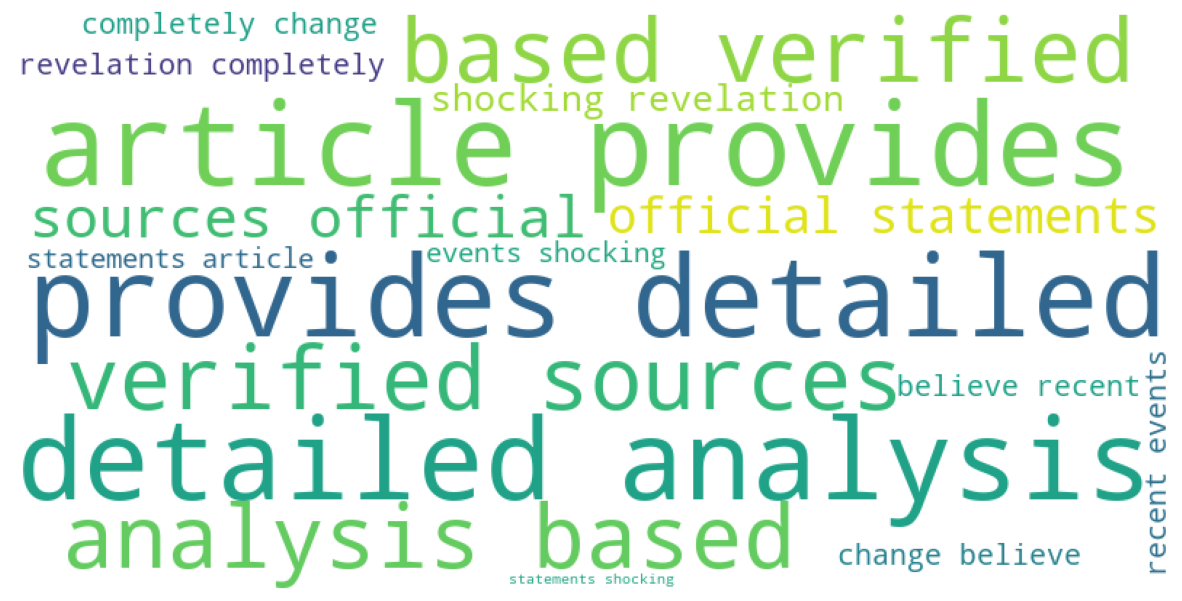

In [47]:
text = " ".join(data["clean_text"])

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(text)

plt.figure(figsize=(15,8))

plt.imshow(wordcloud)

plt.axis("off")

plt.show()

In [48]:
bow = CountVectorizer(max_features=5000)
X_bow = bow.fit_transform(data["clean_text"])
print(X_bow.shape)

(1200, 16)


In [49]:
print(bow.get_feature_names_out())

['analysis' 'article' 'based' 'believe' 'change' 'completely' 'detailed'
 'events' 'official' 'provides' 'recent' 'revelation' 'shocking' 'sources'
 'statements' 'verified']


In [50]:
tfidf = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf.fit_transform(data["clean_text"])
print(X_tfidf.shape)

(1200, 16)


In [51]:
print(tfidf.get_feature_names_out())
print(X_tfidf.toarray())

['analysis' 'article' 'based' 'believe' 'change' 'completely' 'detailed'
 'events' 'official' 'provides' 'recent' 'revelation' 'shocking' 'sources'
 'statements' 'verified']
[[0.33333333 0.33333333 0.33333333 ... 0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333 ... 0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333 ... 0.33333333 0.33333333 0.33333333]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


In [52]:
y = data["label"]
print(y.head())

0    0
1    0
2    0
3    0
4    0
Name: label, dtype: int64


In [53]:
import pickle
pickle.dump(bow, open("bow_vectorizer.pkl", "wb"))
pickle.dump(tfidf, open("tfidf_vectorizer.pkl", "wb"))

In [54]:
data.to_csv("Week2_Final_Dataset.csv", index=False)
print("="*50)
print("Week 2 Completed Successfully")
print("="*50)
print("✔ Exploratory Data Analysis Completed")
print("✔ Bar Charts Generated")
print("✔ Word Count Analysis Completed")
print("✔ Word Cloud Generated")
print("✔ Bag of Words Created")
print("✔ TF-IDF Created")
print("✔ Feature Vectors Saved")
print("="*50)

Week 2 Completed Successfully
✔ Exploratory Data Analysis Completed
✔ Bar Charts Generated
✔ Word Count Analysis Completed
✔ Word Cloud Generated
✔ Bag of Words Created
✔ TF-IDF Created
✔ Feature Vectors Saved


In [55]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.neural_network import MLPClassifier

import pickle

In [56]:
data = pd.read_csv("Week2_Final_Dataset.csv")
print(data)

        id                                         title  \
0        1       Official Report on Politics Development   
1        2  Official Report on Entertainment Development   
2        3       Official Report on Politics Development   
3        4       Official Report on Politics Development   
4        5       Official Report on Politics Development   
...    ...                                           ...   
1195  1196       Shocking Truth About Business Revealed!   
1196  1197  Shocking Truth About Entertainment Revealed!   
1197  1198     Shocking Truth About Technology Revealed!   
1198  1199     Shocking Truth About Technology Revealed!   
1199  1200     Shocking Truth About Technology Revealed!   

                                              full_text      source_name  \
0     This article provides detailed analysis based ...              BBC   
1     This article provides detailed analysis based ...          Reuters   
2     This article provides detailed analysis based

In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(data["clean_text"])

In [58]:
y = data["label"]
print(y.head())

0    0
1    0
2    0
3    0
4    0
Name: label, dtype: int64


In [59]:
X_train, X_test, y_train, y_test = train_test_split(

X,

y,

test_size=0.20,

random_state=42

)
print(X_train.shape)
print(X_test.shape)

(960, 16)
(240, 16)


In [60]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)
pred_lr = lr.predict(X_test)
pickle.dump(lr,open("LogisticRegression.pkl","wb"))

In [61]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,y_train)
pred_knn = knn.predict(X_test)
pickle.dump(knn,open("KNN.pkl","wb"))

In [62]:
rf = RandomForestClassifier(

n_estimators=100,

random_state=42

)
rf.fit(X_train,y_train)
pred_rf = rf.predict(X_test)
pickle.dump(rf,open("RandomForest.pkl","wb"))

In [63]:
nn = MLPClassifier(

hidden_layer_sizes=(100,),

max_iter=300,

random_state=42

)
nn.fit(X_train,y_train)
pred_nn = nn.predict(X_test)
pickle.dump(nn,open("NeuralNetwork.pkl","wb"))

In [64]:
pickle.dump(tfidf,open("TFIDF.pkl","wb"))
print("Actual Labels")

print(y_test.head())

Actual Labels
1178    1
865     1
101     0
439     0
58      0
Name: label, dtype: int64


In [65]:
print("Logistic Regression Predictions")

print(pred_lr[:5])

Logistic Regression Predictions
[1 1 0 0 0]


In [66]:
print("Random Forest Predictions")

print(pred_rf[:5])

Random Forest Predictions
[1 1 0 0 0]


In [67]:
results = pd.DataFrame({

"Actual":y_test.values,

"Logistic":pred_lr,

"KNN":pred_knn,

"RandomForest":pred_rf,

"NeuralNet":pred_nn

})

print(results.head())

   Actual  Logistic  KNN  RandomForest  NeuralNet
0       1         1    1             1          1
1       1         1    1             1          1
2       0         0    0             0          0
3       0         0    0             0          0
4       0         0    0             0          0


In [68]:
results.to_csv("PredictionResults.csv",index=False)
print("="*50)

print("Week 3 Completed Successfully")

print("="*50)

print("✔ Dataset Split")

print("✔ Logistic Regression Trained")

print("✔ KNN Trained")

print("✔ Random Forest Trained")

print("✔ Neural Network Trained")

print("✔ Predictions Generated")

print("✔ Models Saved")

print("="*50)

Week 3 Completed Successfully
✔ Dataset Split
✔ Logistic Regression Trained
✔ KNN Trained
✔ Random Forest Trained
✔ Neural Network Trained
✔ Predictions Generated
✔ Models Saved


In [69]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import pickle

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [70]:
data = pd.read_csv("Week2_Final_Dataset.csv")
print(data)

        id                                         title  \
0        1       Official Report on Politics Development   
1        2  Official Report on Entertainment Development   
2        3       Official Report on Politics Development   
3        4       Official Report on Politics Development   
4        5       Official Report on Politics Development   
...    ...                                           ...   
1195  1196       Shocking Truth About Business Revealed!   
1196  1197  Shocking Truth About Entertainment Revealed!   
1197  1198     Shocking Truth About Technology Revealed!   
1198  1199     Shocking Truth About Technology Revealed!   
1199  1200     Shocking Truth About Technology Revealed!   

                                              full_text      source_name  \
0     This article provides detailed analysis based ...              BBC   
1     This article provides detailed analysis based ...          Reuters   
2     This article provides detailed analysis based

In [71]:
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(data["clean_text"])

y = data["label"]

In [72]:
X_train,X_test,y_train,y_test = train_test_split(

X,

y,

test_size=0.20,

random_state=42
)

In [73]:
lr = pickle.load(open("LogisticRegression.pkl","rb"))

knn = pickle.load(open("KNN.pkl","rb"))

rf = pickle.load(open("RandomForest.pkl","rb"))

nn = pickle.load(open("NeuralNetwork.pkl","rb"))

In [74]:
pred_lr = lr.predict(X_test)
pred_knn = knn.predict(X_test)
pred_rf = rf.predict(X_test)
pred_nn = nn.predict(X_test)

In [75]:
accuracy_score(y_test,pred_lr)
acc_lr = accuracy_score(y_test,pred_lr)

acc_knn = accuracy_score(y_test,pred_knn)

acc_rf = accuracy_score(y_test,pred_rf)

acc_nn = accuracy_score(y_test,pred_nn)
print(acc_lr)

print(acc_knn)

print(acc_rf)

print(acc_nn)

1.0
1.0
1.0
1.0


In [76]:
recall_score(y_test,pred_lr)
rec_lr = recall_score(y_test,pred_lr)

rec_knn = recall_score(y_test,pred_knn)

rec_rf = recall_score(y_test,pred_rf)

rec_nn = recall_score(y_test,pred_nn)

In [77]:
f1_score(y_test,pred_lr)
f1_lr = f1_score(y_test,pred_lr)

f1_knn = f1_score(y_test,pred_knn)

f1_rf = f1_score(y_test,pred_rf)

f1_nn = f1_score(y_test,pred_nn)

In [78]:
print(classification_report(y_test,pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       122
           1       1.00      1.00      1.00       118

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



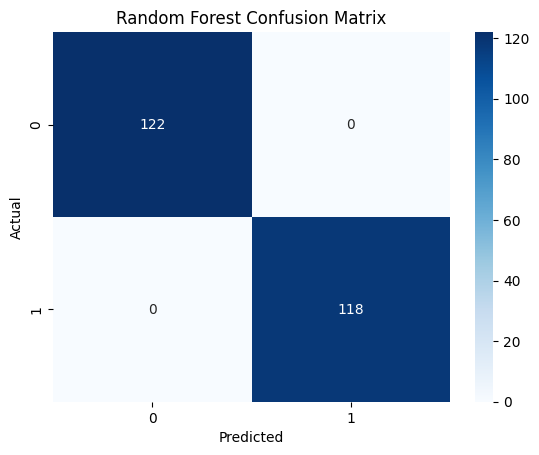

In [79]:
cm = confusion_matrix(y_test,pred_rf)
sns.heatmap(

cm,

annot=True,

fmt="d",

cmap="Blues"

)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.show()

In [80]:
from sklearn.metrics import precision_score
pre_lr = precision_score(y_test, pred_lr)
pre_knn = precision_score(y_test, pred_knn)
pre_rf = precision_score(y_test, pred_rf)
pre_nn = precision_score(y_test, pred_nn)

print(pre_lr)
print(pre_knn)
print(pre_rf)
print(pre_nn)
results = pd.DataFrame({

"Model":["Logistic","KNN","Random Forest","Neural Network"],

"Accuracy":[acc_lr,acc_knn,acc_rf,acc_nn],

"Precision":[pre_lr,pre_knn,pre_rf,pre_nn],

"Recall":[rec_lr,rec_knn,rec_rf,rec_nn],

"F1 Score":[f1_lr,f1_knn,f1_rf,f1_nn]

})

print(results)

1.0
1.0
1.0
1.0
            Model  Accuracy  Precision  Recall  F1 Score
0        Logistic       1.0        1.0     1.0       1.0
1             KNN       1.0        1.0     1.0       1.0
2   Random Forest       1.0        1.0     1.0       1.0
3  Neural Network       1.0        1.0     1.0       1.0


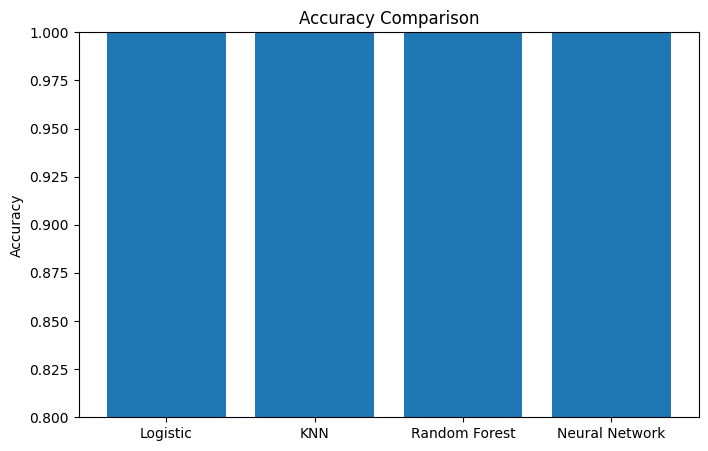

In [81]:
plt.figure(figsize=(8,5))

plt.bar(results["Model"],results["Accuracy"])

plt.title("Accuracy Comparison")

plt.ylabel("Accuracy")

plt.ylim(0.80,1.00)

plt.show()

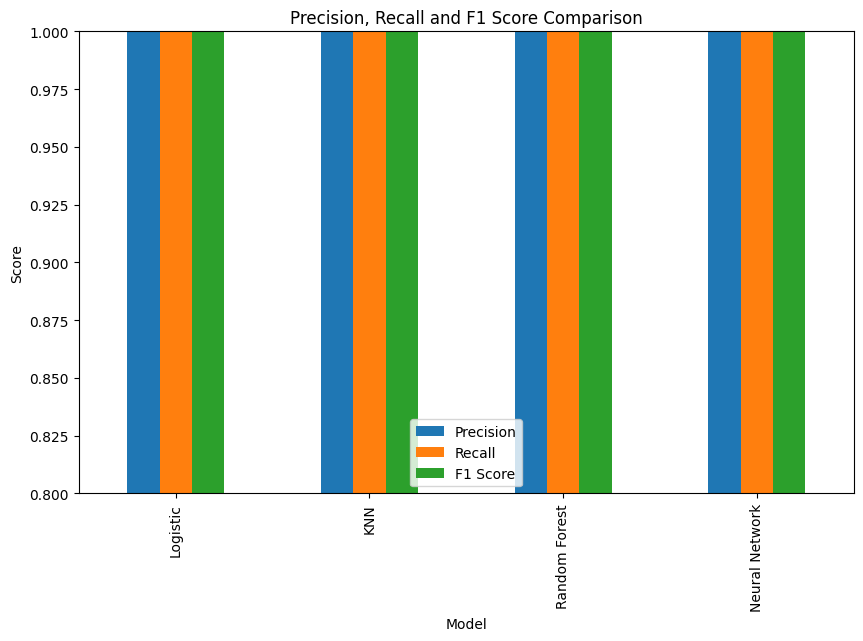

In [82]:
results.set_index("Model")[["Precision", "Recall", "F1 Score"]].plot(kind="bar", figsize=(10,6))

plt.title("Precision, Recall and F1 Score Comparison")

plt.ylabel("Score")

plt.ylim(0.80,1.00)

plt.show()

In [83]:
import os

print(os.getcwd())

C:\Users\Jahnvi Pandey


In [84]:
import glob
import os

pkl_files = glob.glob("*.pkl")

for file in pkl_files:
    print(os.path.abspath(file))

C:\Users\Jahnvi Pandey\bow_vectorizer.pkl
C:\Users\Jahnvi Pandey\KNN.pkl
C:\Users\Jahnvi Pandey\LogisticRegression.pkl
C:\Users\Jahnvi Pandey\naive_bayes.pkl
C:\Users\Jahnvi Pandey\NeuralNetwork.pkl
C:\Users\Jahnvi Pandey\neural_network.pkl
C:\Users\Jahnvi Pandey\RandomForest.pkl
C:\Users\Jahnvi Pandey\TFIDF.pkl
C:\Users\Jahnvi Pandey\tfidf_vectorizer.pkl


In [85]:
import os

for root, dirs, files in os.walk(r"C:\Users\YourName"):
    for file in files:
        if file.endswith(".pkl"):
            print(os.path.join(root, file))

In [86]:
import glob
import os

pkl_files = glob.glob("*.pkl")

for file in pkl_files:
    print(os.path.abspath(file))

C:\Users\Jahnvi Pandey\bow_vectorizer.pkl
C:\Users\Jahnvi Pandey\KNN.pkl
C:\Users\Jahnvi Pandey\LogisticRegression.pkl
C:\Users\Jahnvi Pandey\naive_bayes.pkl
C:\Users\Jahnvi Pandey\NeuralNetwork.pkl
C:\Users\Jahnvi Pandey\neural_network.pkl
C:\Users\Jahnvi Pandey\RandomForest.pkl
C:\Users\Jahnvi Pandey\TFIDF.pkl
C:\Users\Jahnvi Pandey\tfidf_vectorizer.pkl
